# 04 — Custos de produção e preços do milho 2ª safra (Paraná)

Monta a base econômica do artigo, em **R$ de dezembro de 2025** (IPCA mensal):

1. **Custo** — série SEAB/DERAL "Milho Safrinha" (`nhistorico_94.xls`, safras 1999/00–2024/25),
   em R$/saca, convertida em R$/ha pela produtividade de referência que a própria DERAL informa.
2. **Custo operacional** — custo total menos a Renda de Fatores (remuneração imputada da terra e do
   capital próprio). A DERAL histórica não separa esse item; a proporção vem da série CONAB do PR
   (`milho_2a_safra_serie_historica_2005-2025.xls`), ano a ano.
3. **Estrutura do custo** — quanto do custo cresce com a produção (por kg) e quanto é gasto por
   hectare na semeadura, a partir do detalhamento DERAL por item (`custos.xlsx`).
4. **Preço** — preço mensal recebido pelo produtor no PR (SEAB/DERAL via Ipeadata), deflacionado mês
   a mês, para atribuir a cada data de semeadura o preço do seu mês de colheita (notebook 05).

**Convenção de ano**: tudo é indexado pelo **ano da colheita** da safrinha. A DERAL rotula por
ano-agrícola ("1999/00" = semeada e colhida em 2000); a CONAB já usa o ano da colheita
("SAFRA DA SECA - 2010", "2ª SAFRA 2025").

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DADOS, RESULTADOS, FIGURAS = RAIZ / "dados", RAIZ / "resultados", RAIZ / "figuras"
RESULTADOS.mkdir(exist_ok=True)
FIGURAS.mkdir(exist_ok=True)

BASE = (2025, 12)  # mês de referência dos valores reais

## 1. Deflator — IPCA mensal

In [2]:
ipca = pd.read_csv(DADOS / "ipca_mensal.csv")  # BCB/SGS série 433, índice base dez/1998 = 100
ipca = ipca.set_index(["ano", "mes"])["indice"]
indice_base = ipca.loc[BASE]


def deflator(ano, mes):
    return indice_base / ipca.loc[(ano, mes)]


print(f"IPCA disponível: {ipca.index.min()} a {ipca.index.max()}; base = {BASE}")

IPCA disponível: (np.int64(1999), np.int64(1)) a (np.int64(2026), np.int64(5)); base = (2025, 12)


## 2. Custo DERAL (R$/ha, real)

A DERAL publica o custo por saca e informa, no rodapé da planilha, a produtividade de referência de
cada período (60, 80, 75, 70 e 80 sc/ha). O custo por hectare é o custo por saca × essa
produtividade. Cada estimativa tem um **mês de referência** (ex. nov/99), usado na deflação.

In [3]:
bruto = pd.read_excel(DADOS / "nhistorico_94.xls", sheet_name="milho_saf", header=None)
deral = bruto.iloc[7:33, [0, 1, 2, 3]].copy()
deral.columns = ["safra", "mes_ref", "var_60kg_nominal", "total_60kg_nominal"]
deral["ano"] = deral["safra"].str.slice(0, 4).astype(int) + 1  # ano da colheita

MESES = {"jan": 1, "fev": 2, "mar": 3, "abr": 4, "mai": 5, "jun": 6,
         "jul": 7, "ago": 8, "set": 9, "out": 10, "nov": 11, "dez": 12}


def ler_mes_ref(v):
    if isinstance(v, pd.Timestamp) or hasattr(v, "year"):
        return v.year, v.month
    m = re.match(r"([a-z]{3})\D*(\d{2})", str(v).strip().lower())
    return 2000 + int(m.group(2)) if int(m.group(2)) < 50 else 1900 + int(m.group(2)), MESES[m.group(1)]


deral[["ano_ref", "mes_ref"]] = deral["mes_ref"].apply(lambda v: pd.Series(ler_mes_ref(v)))


def produtividade_referencia_sc(ano_colheita):  # rodapé da planilha DERAL
    safra_inicio = ano_colheita - 1
    if safra_inicio <= 2003:
        return 60
    if safra_inicio <= 2005:
        return 80
    if safra_inicio == 2006:
        return 75
    if safra_inicio <= 2014:
        return 70
    return 80


deral["prod_ref_kg_ha"] = deral["ano"].map(produtividade_referencia_sc) * 60
deral["fator_deflator"] = [deflator(a, m) for a, m in zip(deral["ano_ref"], deral["mes_ref"])]
for tipo in ["var", "total"]:
    deral[f"custo_{tipo}_real_ha"] = (
        deral[f"{tipo}_60kg_nominal"].astype(float) * deral["prod_ref_kg_ha"] / 60 * deral["fator_deflator"]
    )
deral[["safra", "ano", "ano_ref", "mes_ref", "prod_ref_kg_ha", "custo_var_real_ha", "custo_total_real_ha"]].round(1)

,safra,ano,ano_ref,mes_ref,prod_ref_kg_ha,custo_var_real_ha,custo_total_real_ha
7,1999/00,2000,1999,11,3600,1817.2,2832.7
8,2000/01,2001,2000,11,3600,1810.2,2906.3
9,2001/02,2002,2001,5,3600,1811.1,2900.8
10,2002/03,2003,2002,12,3600,1818.4,3138.1
11,2003/04,2004,2003,11,3600,2082.9,3633.0
12,2004/05,2005,2004,11,4800,1999.6,3660.5
13,2005/06,2006,2005,11,4800,2203.7,3790.9
14,2006/07,2007,2006,11,4500,1745.2,3178.9
15,2007/08,2008,2007,11,4200,1754.5,3178.3
16,2008/09,2009,2008,11,4200,2242.0,3894.7


## 3. Renda de Fatores / Custo Total — série CONAB (PR)

Em cada aba do Paraná (6 municípios), localiza as linhas "Total de Renda de Fatores" e "Custo
Total" e toma o primeiro valor numérico (R$/ha). A coluna de participação (%) da planilha não é
usada porque muda de escala entre layouts. A proporção do ano é a média dos municípios disponíveis.

In [4]:
xls = pd.ExcelFile(DADOS / "milho_2a_safra_serie_historica_2005-2025.xls")
PADRAO = re.compile(r"^(.*)-PR-(\d{4})$")


def valor_do_rotulo(linha, prefixo):
    """Primeiro número à direita da célula cujo texto começa com `prefixo` (o layout muda entre anos)."""
    for j, v in enumerate(linha):
        if isinstance(v, str) and v.strip().upper().startswith(prefixo):
            for w in linha[j + 1:]:
                if isinstance(w, (int, float)) and pd.notna(w):
                    return float(w)
    return None


registros = []
for aba in xls.sheet_names:
    m = PADRAO.match(aba)
    if not m:
        continue
    df = xls.parse(aba, header=None)
    rf = ct = np.nan
    for linha in df.itertuples(index=False):
        linha = list(linha)
        rf = valor_do_rotulo(linha, "TOTAL DE RENDA DE FATORES") or rf
        ct = valor_do_rotulo(linha, "CUSTO TOTAL") or ct
    registros.append({"cidade": m.group(1), "ano": int(m.group(2)), "renda_fatores": rf, "custo_total": ct})

conab = pd.DataFrame(registros)
conab["ratio"] = conab["renda_fatores"] / conab["custo_total"]
print("Abas sem leitura:", conab["ratio"].isna().sum(), "de", len(conab))
ratio_rf = conab.groupby("ano")["ratio"].agg(["mean", "std", "count"])
ratio_rf.round(3).T

Abas sem leitura: 4 de 85


ano,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
mean,0.212,0.184,0.189,0.220,0.192,0.186,0.190,0.193,0.187,0.171,...,0.322,0.341,0.367,0.218,0.195,0.062,0.16,0.309,0.286,0.278
std,0.031,NaN,NaN,0.063,0.075,0.069,0.058,0.068,0.066,0.036,...,0.064,0.069,0.024,0.018,0.039,0.018,0.05,0.085,0.060,0.060
count,2.000,1.000,1.000,2.000,2.000,2.000,2.000,2.000,2.000,3.000,...,3.000,3.000,3.000,3.000,5.000,5.000,5.00,4.000,5.000,5.000


## 4. Estrutura do custo: por hectare × por quilo

No detalhamento DERAL por item (`custos.xlsx`, milho 2ª safra, 80 sc/ha, 5 datas entre mai/2025 e
mai/2026), o único item do custo variável proporcional à produção é o **transporte externo**;
semente, fertilizante, defensivo, operações, seguro/PROAGRO e juros são gastos por hectare,
comprometidos na semeadura e não recuperados numa quebra de safra.

In [5]:
det = pd.read_excel(DADOS / "custos.xlsx", sheet_name="so_a_base", header=None)
datas = det.iloc[4, 7:12].tolist()
itens = det.iloc[5:, [1, 5] + list(range(7, 12))]
itens.columns = ["cultura", "item"] + [pd.Timestamp(d).strftime("%Y-%m") for d in datas]
milho2 = itens[itens["cultura"] == 7].set_index("item").drop(columns="cultura")
milho2 = milho2.apply(pd.to_numeric, errors="coerce").fillna(0)

ITENS_VARIAVEIS = ["Operação de máquinas e implementos", "Despesas de manutenção de benfeitorias",
                   "Mão-de-obra temporária", "Sementes/Manivas", "Fertilizantes", "Agrotóxicos",
                   "Despesas gerais", "Transporte externo", "Assistência técnica", "PROAGRO/SEGURO", "Juros"]
ITENS_RENDA_FATORES = ["Remuneração do Capital próprio", "Remuneração da terra"]

custo_var_det = milho2.loc[ITENS_VARIAVEIS].sum()
frac_por_kg = milho2.loc["Transporte externo"] / custo_var_det
ratio_rf_deral_atual = milho2.loc[ITENS_RENDA_FATORES].sum() / milho2.sum()

FRACAO_VAR_POR_KG = float(frac_por_kg.mean())
print("Fração do custo variável proporcional à produção (transporte):", frac_por_kg.round(3).to_dict())
print(f"→ usada: {FRACAO_VAR_POR_KG:.3f}")
print("Renda de Fatores / Custo Total no detalhamento DERAL atual:", ratio_rf_deral_atual.round(3).to_dict())
print("Mesma proporção na CONAB 2025:", round(ratio_rf.loc[2025, "mean"], 3) if 2025 in ratio_rf.index else "—")

Fração do custo variável proporcional à produção (transporte): {'2025-05': 0.088, '2025-08': 0.086, '2025-11': 0.089, '2026-02': 0.087, '2026-05': 0.083}
→ usada: 0.087
Renda de Fatores / Custo Total no detalhamento DERAL atual: {'2025-05': 0.305, '2025-08': 0.3, '2025-11': 0.304, '2026-02': 0.305, '2026-05': 0.287}
Mesma proporção na CONAB 2025: 0.278


## 5. Série final de custos

- `custo_operacional_real_ha` = custo total × (1 − Renda de Fatores/Custo Total) — **cenário
  principal**: a decisão de semear a safrinha após a soja não paga de novo a terra.
- `custo_total_real_ha` — cenário de sensibilidade (custo econômico pleno).
- Cada cenário é dividido em parte por hectare (`*_ha_fixo`) e parte por kg (`custo_var_real_kg`).

In [6]:
custos = deral.set_index("ano")[["safra", "ano_ref", "mes_ref", "prod_ref_kg_ha",
                                 "custo_var_real_ha", "custo_total_real_ha"]].copy()
custos["ratio_renda_fatores"] = ratio_rf["mean"].reindex(custos.index)
custos["ratio_interpolado"] = custos["ratio_renda_fatores"].isna()
custos["ratio_renda_fatores"] = custos["ratio_renda_fatores"].interpolate(limit_direction="both")

custos["custo_operacional_real_ha"] = custos["custo_total_real_ha"] * (1 - custos["ratio_renda_fatores"])
custos["custo_var_real_kg"] = FRACAO_VAR_POR_KG * custos["custo_var_real_ha"] / custos["prod_ref_kg_ha"]
parte_por_kg_ref = FRACAO_VAR_POR_KG * custos["custo_var_real_ha"]
custos["custo_operacional_ha_fixo"] = custos["custo_operacional_real_ha"] - parte_por_kg_ref
custos["custo_total_ha_fixo"] = custos["custo_total_real_ha"] - parte_por_kg_ref

print("Anos com proporção interpolada:", custos.index[custos["ratio_interpolado"]].tolist())
custos.to_csv(RESULTADOS / "custos_milho_safrinha_real.csv")
custos.round(2)

Anos com proporção interpolada: []


,safra,ano_ref,mes_ref,prod_ref_kg_ha,custo_var_real_ha,custo_total_real_ha,ratio_renda_fatores,ratio_interpolado,custo_operacional_real_ha,custo_var_real_kg,custo_operacional_ha_fixo,custo_total_ha_fixo
ano,,,,,,,,,,,,
2000,1999/00,1999,11,3600,1817.22,2832.72,0.18,False,2311.38,0.04,2153.92,2675.26
2001,2000/01,2000,11,3600,1810.15,2906.33,0.19,False,2357.39,0.04,2200.54,2749.48
2002,2001/02,2001,5,3600,1811.06,2900.79,0.22,False,2262.81,0.04,2105.88,2743.86
2003,2002/03,2002,12,3600,1818.38,3138.07,0.19,False,2534.52,0.04,2376.95,2980.50
2004,2003/04,2003,11,3600,2082.88,3633.02,0.19,False,2958.33,0.05,2777.85,3452.54
2005,2004/05,2004,11,4800,1999.57,3660.48,0.19,False,2963.35,0.04,2790.08,3487.22
2006,2005/06,2005,11,4800,2203.73,3790.88,0.19,False,3060.58,0.04,2869.63,3599.93
2007,2006/07,2006,11,4500,1745.18,3178.86,0.19,False,2584.94,0.03,2433.72,3027.64
2008,2007/08,2007,11,4200,1754.48,3178.32,0.17,False,2636.22,0.04,2484.19,3026.30


## 6. Preços mensais recebidos pelo produtor (PR)

In [7]:
ipea = pd.read_csv(DADOS / "ipea_precos_milho_mensal.csv")
precos = ipea[(ipea["sercodigo"] == "DERAL12_PRMI12") & (ipea["ano"] >= 1999)].copy()
precos = precos[precos.set_index(["ano", "mes"]).index.isin(ipca.index)].reset_index(drop=True)

# Erros de digitação na fonte (ex. jul/2023 = R$ 215/sc): valor > 2× a mediana dos 2 meses de cada
# lado é substituído pela média dos meses vizinhos.
viz = precos["valor"].rolling(5, center=True, min_periods=3).median()
erro = precos["valor"] > 2 * viz
print("Corrigidos na fonte:", precos.loc[erro, ["ano", "mes", "valor"]].to_dict("records"))
precos.loc[erro, "valor"] = (precos["valor"].shift(1) + precos["valor"].shift(-1))[erro] / 2

precos["preco_real_60kg"] = [v * deflator(a, m) for v, a, m in zip(precos["valor"], precos["ano"], precos["mes"])]
precos["preco_real_kg"] = precos["preco_real_60kg"] / 60
precos = precos.rename(columns={"valor": "preco_nominal_60kg"})[["ano", "mes", "preco_nominal_60kg",
                                                                  "preco_real_60kg", "preco_real_kg"]]
precos.to_csv(RESULTADOS / "precos_milho_pr_mensal_real.csv", index=False)

sazonal = precos.assign(rel=precos["preco_real_60kg"] / precos.groupby("ano")["preco_real_60kg"].transform("mean"))
indice_sazonal = sazonal.groupby("mes")["rel"].agg(["mean", "std"])
indice_sazonal.round(3).T

Corrigidos na fonte: [{'ano': 2023, 'mes': 7, 'valor': 215.0561}]


mes,1,2,3,4,5,6,7,8,9,10,11,12
mean,1.034,1.028,1.025,0.999,0.986,0.97,0.949,0.960,0.979,1.000,1.036,1.032
std,0.162,0.143,0.118,0.107,0.105,0.09,0.083,0.086,0.084,0.119,0.185,0.190


## 7. Figura — custo e preço reais

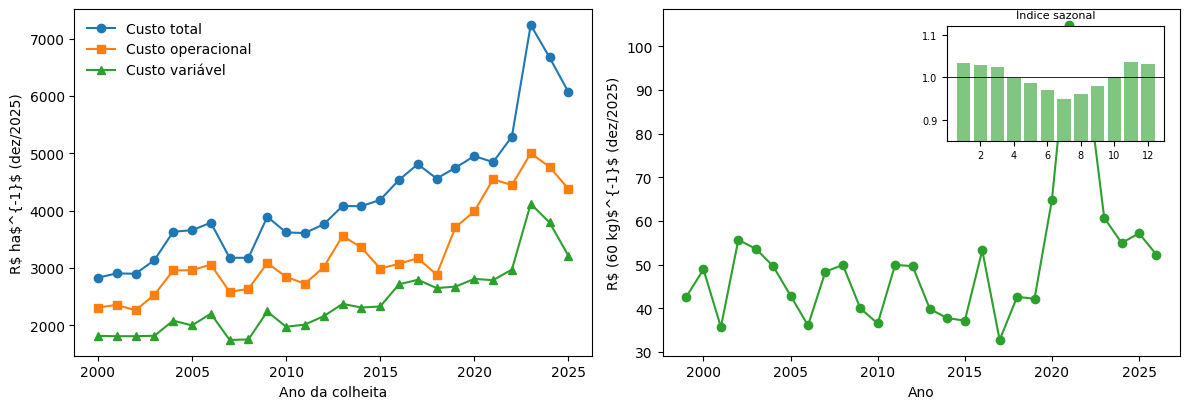

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
a1.plot(custos.index, custos["custo_total_real_ha"], "o-", label="Custo total")
a1.plot(custos.index, custos["custo_operacional_real_ha"], "s-", label="Custo operacional")
a1.plot(custos.index, custos["custo_var_real_ha"], "^-", label="Custo variável")
a1.set(xlabel="Ano da colheita", ylabel="R$ ha$^{-1}$ (dez/2025)")
a1.legend(frameon=False)
anual = precos.groupby("ano")["preco_real_60kg"].mean()
a2.plot(anual.index, anual.values, "o-", color="tab:green", label="Média anual")
a2.set(xlabel="Ano", ylabel="R$ (60 kg)$^{-1}$ (dez/2025)")
ax_in = a2.inset_axes([0.55, 0.62, 0.42, 0.33])
ax_in.bar(indice_sazonal.index, indice_sazonal["mean"], color="tab:green", alpha=0.6)
ax_in.axhline(1, color="k", lw=0.6)
ax_in.set_ylim(0.85, 1.12)
ax_in.set_title("Índice sazonal", fontsize=8)
ax_in.tick_params(labelsize=7)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_custos_precos.png", dpi=300)